# Giai đoạn 3 — Khám phá dữ liệu

Sau khi hiểu cấu trúc dữ liệu và đọc quy tắc tiền xử lý, xem hai góc nhìn dùng cho các bài toán phía sau. Chuỗi ngày đến trực tiếp từ bảng Sales. Hồ sơ khách hàng đến từ bộ RFM của các đơn delivered.

In [1]:
from pathlib import Path
import json
import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next(
    (path for path in (start, *start.parents)
     if (path / "notebook/00_ham_dung_chung.ipynb").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")

support_file = ROOT / "notebook/00_ham_dung_chung.ipynb"
support_doc = json.loads(support_file.read_text(encoding="utf-8"))
loader = "".join(support_doc["cells"][1]["source"])
exec(compile(loader, str(support_file), "exec"), {"SUPPORT_FILE": support_file})
from datathon.runtime import read_reference, reference_path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown
from datathon.segmentation.study import concentration

%matplotlib inline
sales = pd.read_csv(ROOT / "data/raw/sales.csv", parse_dates=["Date"]).sort_values("Date")
rfm = pd.read_csv(
    ROOT / "data/model/phan_khuc/v1/rfm_exact.csv",
    dtype={"customer_id": str},
)


## Doanh thu và giá vốn biến động theo thời gian

Cộng các chỉ tiêu theo tháng để nhìn xu hướng, rồi đếm số ngày giá vốn cao hơn doanh thu trên chuỗi gốc. Chỉ tiêu Revenue − COGS mô tả chênh lệch hai cột của bảng Sales.

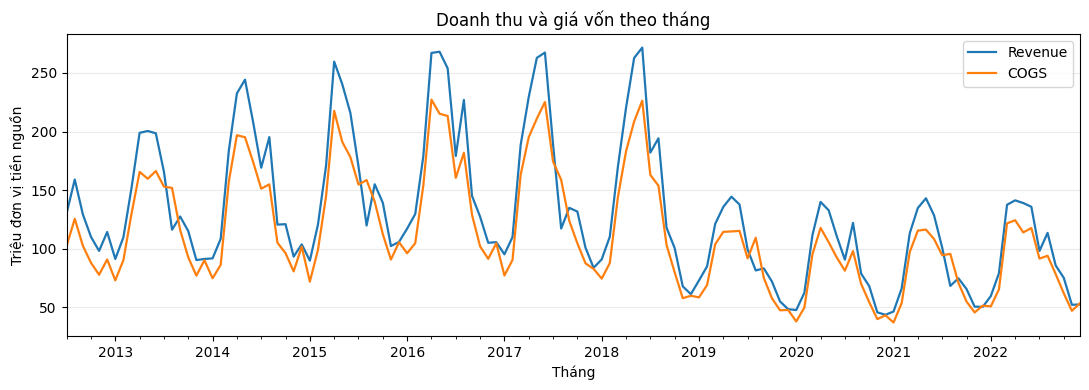

**382/3,833 ngày** có COGS cao hơn Revenue. NV01.3–NV01.4 phân tích các giai đoạn biến động và tính thời vụ.

In [2]:
monthly = sales.groupby(sales["Date"].dt.to_period("M"))[["Revenue", "COGS"]].sum()
monthly.index = monthly.index.to_timestamp()
ax = (monthly / 1_000_000).plot(figsize=(11, 4), linewidth=1.6)
ax.set(
    title="Doanh thu và giá vốn theo tháng",
    xlabel="Tháng",
    ylabel="Triệu đơn vị tiền nguồn",
)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

days = int(sales["COGS"].gt(sales["Revenue"]).sum())
display(Markdown(f"**{days:,}/{len(sales):,} ngày** có COGS cao hơn Revenue. "
                 "NV01.3–NV01.4 phân tích các giai đoạn biến động và tính thời vụ."))


## Giá trị mua hàng tập trung ở nhóm khách nào?

Monetary là Net hàng hóa của các đơn delivered được tính trong RFM, với ngày chốt 31/12/2022. Xếp khách theo Monetary giảm dần và tính mỗi nhóm top đóng góp bao nhiêu vào tổng Monetary của tập khách đủ điều kiện.

In [3]:
shares = concentration(rfm)
view = shares.rename(columns={
    "top_customer_fraction": "Tỷ lệ khách top",
    "selected_customers": "Số khách",
    "monetary_share": "Tỷ trọng Monetary",
})
display(view.style.format({"Tỷ lệ khách top": "{:.0%}", "Tỷ trọng Monetary": "{:.1%}"}))
top_20_share = shares.loc[shares["top_customer_fraction"].eq(0.20), "monetary_share"].item()
display(Markdown(f"**20% khách đứng đầu đóng góp {top_20_share:.1%} Monetary.** "
                 "PC02 dùng phân phối RFM để xem xét log và chuẩn hóa trước phân cụm."))


,Tỷ lệ khách top,Số khách,Tỷ trọng Monetary
0,1%,852,7.1%
1,5%,4256,24.2%
2,10%,8512,39.1%
3,20%,17023,59.5%
4,50%,42558,89.0%


**20% khách đứng đầu đóng góp 59.5% Monetary.** PC02 dùng phân phối RFM để xem xét log và chuẩn hóa trước phân cụm.

## Đọc tiếp

- [Bài 1 — NV01](../04_phan_tich_kinh_doanh/NV01_phan_tich_ban_hang.ipynb) đọc diễn biến, bất thường và tính thời vụ theo nhiều cấp thời gian.
- [Bài 2 — PC02](../05_phan_khuc_khach_hang/PC02_phan_tich_rfm_va_dac_trung.ipynb) đọc phân bố RFM, sự tập trung và lựa chọn đặc trưng.
- [Bài 3 — Baseline](../06_du_bao/baseline.ipynb) dùng chuỗi Sales lịch sử để minh họa dự báo trên lịch của mẫu nộp bài.